### Task 1: Univariate Linear Regression from Scratch using Batch Gradient Descent (Linear Regression From Scratch)

(30, 2)
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
YearsExperience    0
Salary             0
dtype: int64
theta0 = 35796.7801, theta1 = 88692.8798
MSE = 39323613.14, R2 = 0.8433


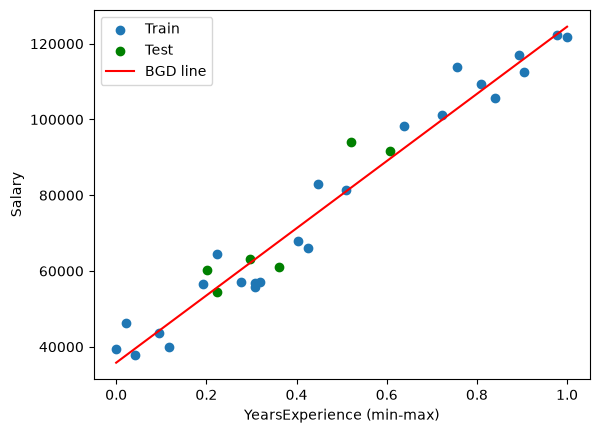

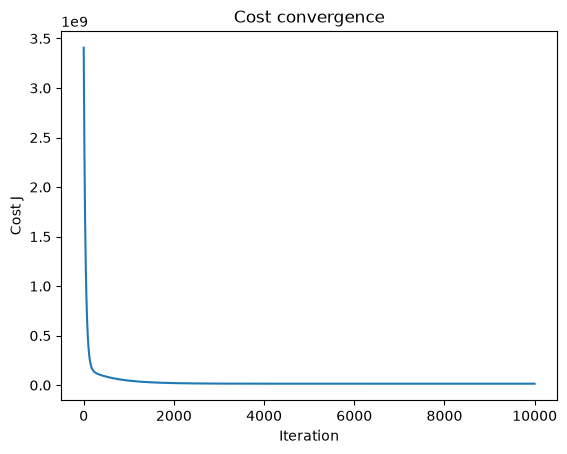

Predicted salary for 5 years: 72594.89


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load dataset
data = pd.read_csv("data/Salary_Data.csv")
print(data.shape); print(data.head()); print(data.isnull().sum())

# Step 2: Remove missing values
data = data.dropna()

#define x
X = data["YearsExperience"].values
#define y
y = data["Salary"].values

# Step 3: Train-test split (80:20)
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx, test_idx = indices[:split], indices[split:]
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Step 4: Min-Max normalization (training statistics only)
x_min, x_max = X_train.min(), X_train.max()
X_train = (X_train - x_min) / (x_max - x_min)
X_test = (X_test - x_min) / (x_max - x_min)

# Step 5: Initialize parameters
m = len(X_train)
theta0 = 0
theta1 = 0
alpha = 0.01
iterations = 10000
cost_history = []

# Step 6: Batch Gradient Descent
for i in range(iterations):
    pred = theta0 + theta1 * X_train
    err = pred - y_train
    cost_history.append((err ** 2).sum() / (2 * m))
    grad0 = err.sum() / m
    grad1 = (err * X_train).sum() / m
    theta0 -= alpha * grad0
    theta1 -= alpha * grad1

# Step 7: Display learned parameters
print(f"theta0 = {theta0:.4f}, theta1 = {theta1:.4f}")

# Step 8: Predict on test data
y_pred = theta0 + theta1 * X_test

# Step 9: MSE and R2 manually
mse = np.mean((y_test - y_pred) ** 2)
r2 = 1 - ((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()
print(f"MSE = {mse:.2f}, R2 = {r2:.4f}")

# Step 10: Plot regression line
xs = np.linspace(0, 1, 100)
plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, c="g", label="Test")
plt.plot(xs, theta0 + theta1 * xs, "r", label="BGD line")
plt.xlabel("YearsExperience (min-max)"); plt.ylabel("Salary"); plt.legend(); plt.show()

# Step 11: Plot cost convergence
plt.plot(cost_history); plt.xlabel("Iteration"); plt.ylabel("Cost J"); plt.title("Cost convergence"); plt.show()

# Step 12: Predict salary for 5 years of experience
x5 = (5 - x_min) / (x_max - x_min)
print(f"Predicted salary for 5 years: {theta0 + theta1 * x5:.2f}")


### Task 2: Univariate Linear Regression using Scikit-learn

Coefficient: 88706.98685420115 Intercept: 35789.58062143776
MSE: 39326046.03955983 R2: 0.8433355166157543
    Actual       Scratch       Sklearn      Diff
0  91738.0  89578.632751  89579.987544  1.354792
1  54445.0  55611.146885  55607.098961 -4.047924
2  63218.0  62215.935804  62212.938408 -2.997396
3  61111.0  67877.183448  67875.086505 -2.096943
4  93940.0  82030.302559  82030.456748  0.154189
5  60150.0  53724.064337  53719.716262 -4.348075
scratch: theta0=35796.78, theta1=88692.88 | sklearn: intercept=35789.58, coef=88706.99


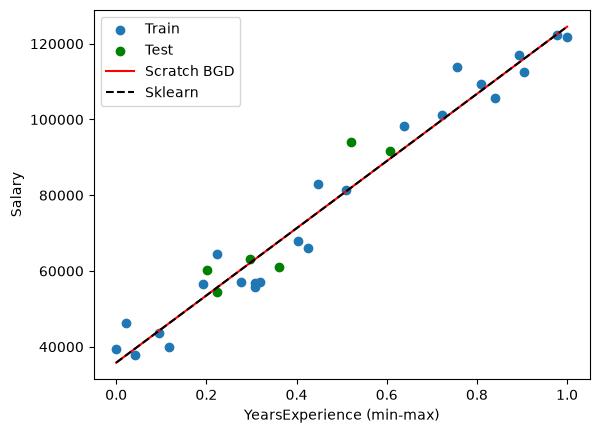

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Load dataset
data = pd.read_csv("data/Salary_Data.csv").dropna()

# Step 2: Prepare X and y
X = data[["YearsExperience"]].values
y = data["Salary"].values

# Step 3: Same split as Task 1 (seed 42 permutation, 80:20)
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, X_test = X[indices[:split]], X[indices[split:]]
y_train, y_test = y[indices[:split]], y[indices[split:]]

# Step 4: Min-Max normalization with training statistics
xmin, xmax = X_train.min(), X_train.max()
X_train = (X_train - xmin) / (xmax - xmin)
X_test = (X_test - xmin) / (xmax - xmin)

# Step 5: Create and train LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

# Step 6: Predictions
y_pred_sk = model.predict(X_test)

# Step 7: Coefficient and intercept
print("Coefficient:", model.coef_[0], "Intercept:", model.intercept_)

# Step 8: MSE and R2
print("MSE:", mean_squared_error(y_test, y_pred_sk), "R2:", r2_score(y_test, y_pred_sk))

# Step 9: Compare with Task 1
y_pred_scratch = theta0 + theta1 * X_test.ravel()
comparison = pd.DataFrame({"Actual": y_test, "Scratch": y_pred_scratch, "Sklearn": y_pred_sk})
comparison["Diff"] = comparison["Sklearn"] - comparison["Scratch"]
print(comparison)
print(f"scratch: theta0={theta0:.2f}, theta1={theta1:.2f} | sklearn: intercept={model.intercept_:.2f}, coef={model.coef_[0]:.2f}")

# Step 10: Plot both regression lines
xs = np.linspace(0, 1, 100)
plt.scatter(X_train, y_train, label="Train"); plt.scatter(X_test, y_test, c="g", label="Test")
plt.plot(xs, theta0 + theta1 * xs, "r", label="Scratch BGD")
plt.plot(xs, model.predict(xs.reshape(-1, 1)), "k--", label="Sklearn")
plt.xlabel("YearsExperience (min-max)"); plt.ylabel("Salary"); plt.legend(); plt.show()


**Discussion.** Both models use identical train/test samples and identical min-max scaling, so the fitted lines should match. Sklearn solves least squares in closed form (exact optimum). Our Batch Gradient Descent approaches that optimum iteratively (alpha=0.01, 10000 iterations); a tiny residual gap in theta0/theta1 and predictions remains because it stops before perfect convergence. With scaled input, convergence is fast enough that the difference is negligible (see Diff column), and MSE / R² are practically identical.

### Task 3: Multivariate Linear Regression using Scikit-learn (Multiple Independent Variables)

Shape: (20640, 8)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
Missing values:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


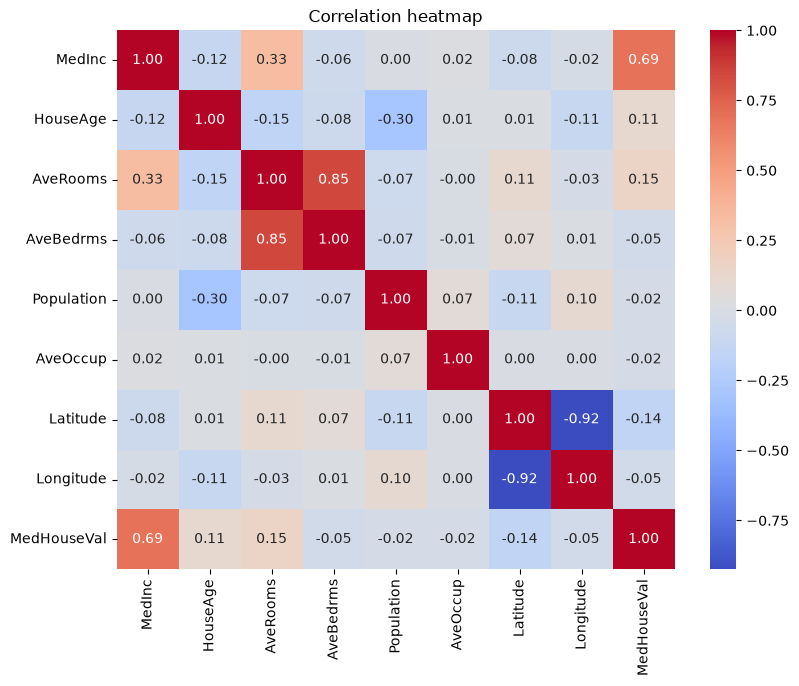

MSE: 0.555891598695244 R2: 0.5757877060324511
Latitude     -0.896929
Longitude    -0.869842
AveRooms     -0.294410
AveOccup     -0.040829
Population   -0.002308
HouseAge      0.122546
AveBedrms     0.339259
MedInc        0.854383
dtype: float64
Intercept: 2.071946937378881
Strongest positive: MedInc 0.8543830309268542
Strongest negative: Latitude -0.896928876638665
    Actual  Predicted
0  0.47700   0.719123
1  0.45800   1.764017
2  5.00001   2.709659
3  2.18600   2.838926
4  2.78000   2.604657
5  1.58700   2.011754
6  1.98200   2.645500
7  1.57500   2.168755
8  3.40000   2.740746
9  4.46600   3.915615


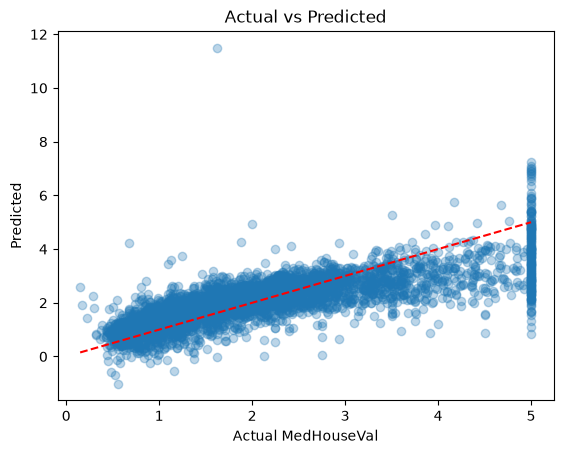

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Load California Housing dataset
housing = fetch_california_housing()

# Step 2: DataFrame
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name="MedHouseVal")

# Step 3: Inspect dataset
print("Shape:", X.shape)
print(X.head())
print("Missing values:\n", X.isnull().sum())

# Step 4: Correlation heatmap (incl. target)
plt.figure(figsize=(9, 7))
sns.heatmap(pd.concat([X, y], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

# Step 5: Train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 6: StandardScaler (fit on train only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Step 7: Train LinearRegression
model = LinearRegression()
model.fit(X_train_s, y_train)

# Step 8: Predictions
y_pred = model.predict(X_test_s)

# Step 9: Evaluate
print("MSE:", mean_squared_error(y_test, y_pred), "R2:", r2_score(y_test, y_pred))

# Step 10: Coefficients
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
print(coefs); print("Intercept:", model.intercept_)

# Step 11: Strongest coefficients
print("Strongest positive:", coefs.idxmax(), coefs.max())
print("Strongest negative:", coefs.idxmin(), coefs.min())

# Step 12: Actual vs predicted
print(pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10]}))

# Step 13: Plot actual vs predicted
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual MedHouseVal"); plt.ylabel("Predicted"); plt.title("Actual vs Predicted"); plt.show()


**Interpretation.** Features are standardized, so coefficient magnitudes are directly comparable: each is the change in house value (in $100k) per one standard deviation increase of that feature, others fixed. `MedInc` has a strong positive effect (richer areas, pricier houses). `Latitude` and `Longitude` have the strongest negative coefficients (prices fall moving north and east, away from the expensive coastal areas). `AveBedrms` is positive while `AveRooms` is negative, a sign of multicollinearity between the two. R² ≈ 0.58 shows a linear model explains only part of the variance.

### Task 4: Logistic Regression from Scratch using Batch Gradient Descent (from scratch)

Malignant: 212 Benign: 357
Learned theta (bias first): [-0.32839486  0.52771603  0.74526989  0.50319786  0.57978915  0.42067885
 -0.29321152  0.71576135  0.87878445 -0.08172903 -0.30336672  1.1758311
 -0.2494929   0.79016746  0.87842616  0.20099605 -0.90182613  0.01302768
  0.38187653 -0.26113983 -0.69376815  0.95781151  1.32996403  0.81473402
  0.93502587  0.70472277 -0.07467227  0.84864919  0.81754388  1.04195499
  0.04630328]
Accuracy : 0.9736842105263158
Precision: 0.975609756097561
Recall   : 0.9523809523809523
F1-score : 0.963855421686747
[[71  1]
 [ 2 40]]


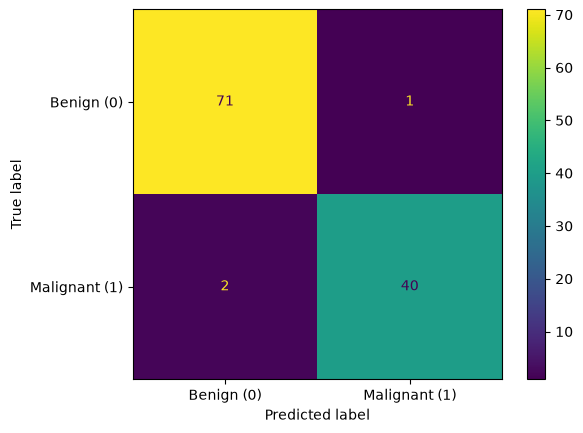

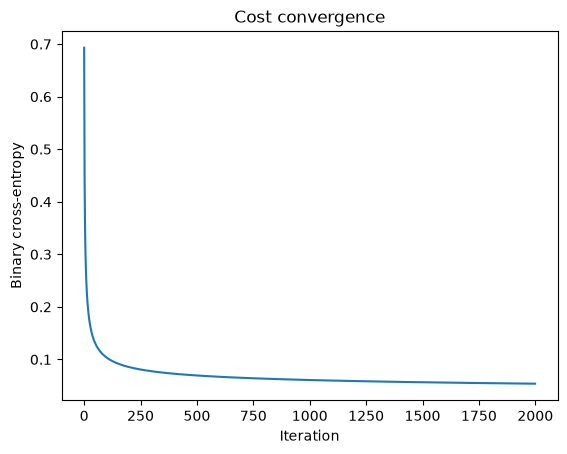

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 1: Load dataset
data = load_breast_cancer()

X = data.data

# sklearn: 0 = malignant, 1 = benign -> flip so malignant=1, benign=0
y = 1 - data.target
print("Malignant:", y.sum(), "Benign:", (y == 0).sum())

# Step 2: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 3: Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 4: Add bias column
X_train = np.c_[np.ones(len(X_train)), X_train]
X_test = np.c_[np.ones(len(X_test)), X_test]

# Step 5: Initialize parameters
m, n = X_train.shape

theta = np.zeros(n)

alpha = 0.1
iterations = 2000

cost_history = []


# Step 6: Sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# Step 7: Binary cross-entropy
def compute_cost(y_true, h):
    eps = 1e-12
    h = np.clip(h, eps, 1 - eps)
    return -np.mean(y_true * np.log(h) + (1 - y_true) * np.log(1 - h))


# Step 8: Batch Gradient Descent
for i in range(iterations):
    z = X_train @ theta
    h = sigmoid(z)
    cost_history.append(compute_cost(y_train, h))
    grad = X_train.T @ (h - y_train) / m
    theta = theta - alpha * grad

print("Learned theta (bias first):", theta)

# Step 9: Probabilities on test data
probs = sigmoid(X_test @ theta)

# Step 10: Threshold 0.5
y_pred = (probs >= 0.5).astype(int)

# Step 11: Metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))

# Step 12: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["Benign (0)", "Malignant (1)"]).plot()
plt.show()

# Step 13: Cost vs iterations
plt.plot(cost_history); plt.xlabel("Iteration"); plt.ylabel("Binary cross-entropy"); plt.title("Cost convergence"); plt.show()


**Interpretation.** A *false negative* (malignant predicted benign) is the dangerous error: a real tumor goes untreated, which is why recall on the malignant class matters most. A *false positive* (benign predicted malignant) causes unnecessary follow-up tests and anxiety but is far less costly. See the confusion matrix above: FN is bottom-left, FP is top-right. If recall needs raising, lower the threshold below 0.5 (trading more false positives for fewer false negatives).

**Result:** 1 false positive and 2 false negatives out of 114 test samples; malignant recall = 0.952.

### Task 5: Customer Churn Prediction Using Logistic Regression

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

              precision    recall  f1-score   support

        Stay       0.83      0.89      0.86      1033
       Churn       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407



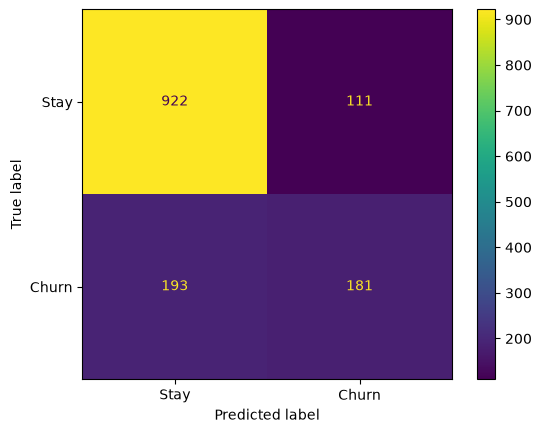

Prediction: Churn (churn probability = 0.663)


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# 2. Load Dataset
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())
print("Shape:", df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("Target variable: Churn")


# 3. Data Preprocessing
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df = df.dropna(subset=["TotalCharges"])  # blank = new customers (tenure 0), only 11 rows
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})


# 4. Select Features and Target
features = ["tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService"]

X = df[features]
y = df["Churn"]

# 5. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Feature Preprocessing
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

categorical_features = ["Contract", "InternetService"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

# 7. Create and Train Model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

# Save trained model
joblib.dump(model, "churn_model.pkl")

###################
# Load saved model
model = joblib.load("churn_model.pkl")

print("Trained model loaded successfully!")

# 8. Make Predictions
y_pred = model.predict(X_test)

# 9. Model Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Stay", "Churn"]))

# 10. Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Stay", "Churn"]).plot()
plt.show()

# 11. Predict a new customer
new = pd.DataFrame([{"tenure": 5, "MonthlyCharges": 85.0, "TotalCharges": 425.0,
                     "Contract": "Month-to-month", "InternetService": "Fiber optic"}])
p = model.predict_proba(new)[0, 1]
print(f"Prediction: {'Churn' if p >= 0.5 else 'Stay'} (churn probability = {p:.3f})")
